In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from collections import defaultdict
import numpy as np
import pytz
import re

In [2]:
# Read the list of filenames from the configuration file
with open('../file_list.txt', 'r', encoding='utf-8') as config_file:
    file_names = config_file.read().splitlines()

# Regex pattern to match the data format
pattern = r'\[(.*?)\] (.*?): (.*)'

# Initialize an empty list to store parsed data
datalist = []
stream_count = 0
# Iterate over each specified file
for file in file_names:
    full_path = f"../data/{file}"
    with open(full_path, 'r', encoding='utf-8') as f:
        lines = f.readlines()
        for line in lines:
            match = re.match(pattern, line)
            if match:
                date, user, message = match.groups()
                datalist.append([date, user, message,stream_count])
    stream_count = stream_count + 1

# Create a DataFrame from the parsed data
data = pd.DataFrame(datalist, columns=["date", "user", "message","stream"])
data['date'] = pd.to_datetime(data['date'])



In [3]:
def convert_utc_to_cet(df, date_column='date'):
    """
    Convert UTC timestamps to Central European Time (CET/CEST) with proper DST handling
    
    Parameters:
    df (pd.DataFrame): DataFrame containing the date column
    date_column (str): Name of the column containing UTC timestamps
    
    Returns:
    pd.DataFrame: DataFrame with converted timestamps
    """
    # Make a copy to avoid modifying the original
    df = df.copy()
    
    # Ensure timestamps are UTC aware
    if df[date_column].dt.tz is None:
        df[date_column] = df[date_column].dt.tz_localize('UTC')
    elif df[date_column].dt.tz != pytz.UTC:
        df[date_column] = df[date_column].dt.tz_convert('UTC')
    
    # Convert to CET/CEST (Europe/Berlin includes proper DST handling)
    df[date_column] = df[date_column].dt.tz_convert('Europe/Berlin')
    
    return df


In [4]:
data = convert_utc_to_cet(data)

In [5]:
data["user"] = data["user"].str.lower()

In [6]:
data['user'] = data['user'].replace({
    '5hreyansh1': 'shreyansh_15_',
    '88krille': 'phrank007',
    'abjectuz': 'albazoarr',
    'aboodorten': 'abood_orton',
    'adevogado0_0': 'adevogado__33',
    'akahoroshi': 'damm1jp',
    'banties1g': 'banties_x',
    'beratnazmm': 'beratnzm0',
    'bickcog158': 'oliver_158',
    'boyy966': 'boy_kaa_',
    'cactiesrn': 'staniv4_',
    'cengizkorkmaz00': 'say_i_love_u_',
    'chabibzzo': 'chabbzz4u',
    'chili_conbacon': 'chili_con_bacon',
    'chili_poe': 'chili_con_bacon',
    'cukululu41': 'aransamus64',
    'drizzienm': 'drizzie3s',
    'elecetric1': 'mediterrn1',
    'emin_ko': 'pepegakun',
    'eminkoo': 'pepegakun',
    'emlnko': 'pepegakun',
    'flexus1771_': 'flexus17_',
    'fr__00': 'firas__00',
    'fyyzckrl': 'n1trx_63',
    'happymetalist': 'kindheadbanger',
    'hella__yeahh': 'hella_yeahh',
    'hellrazor_0': 'hellrazor_1',
    'honey2024': 'honneeeeyyy',
    'internetuser3708776': 'notdylll',
    'io69oi': 'dterreneitorb',
    'iomwmoi': 'dterreneitorb',
    'jbinsamboosa': 'jbin2036',
    'jermsywermsy': 'chromejeromee',
    'journee_': 'journee',
    'justlogannnnn': 'loganxdr',
    'karasusora7': '777ultima777',
    'kecso1g': 'kkecso',
    'lajosbarnabas': 'lajoss__',
    'lighttx_': 'lightfx_',
    'luke_nukem118': 'duke_lukem5',
    'lytis_': 'lightfx_',
    'm7mdess': 'kasida_ink',
    'make_matovic_greatagain': 'freemaaan_',
    'mamangracing13': 'iamsatire_',
    'marcusbarcus1': 'marcus_15s',
    'methmethician': 'permission_cheese',
    'muffineater27': 'sillylittlemuffinn',
    'muffinmmn': 'sillylittlemuffinn',
    'n0rth0m': 's4sk__',
    'nat_l0ve': 'scentless_',
    'necrolutz': 'xvette06',
    'nishad_more1311': 'nishad13',
    'nobodysbv': 'fein_bv',
    'nojokeee1': 'magor_35',
    'nuffsaid_17': 'aransamus64',
    'opalshbab7': 'opalmyzeis',
    'orez_prajit': 'luchian03',
    'paulpige0n': 'pige0n98',
    'pepega_kun': 'pepegakun',
    'rizz_lord_69': 'pepegakun',
    'rodrigo_200771': 'rodrigo_20771',
    's4sk____': 's4sk__',
    'sahilsd97': 'unemployedking69',
    'schiken44': 'aransamus64',
    'sheerchild': 'veryloyalgamingfrog',
    'softarballt123': 'softarr',
    'softarballtt': 'softarr',
    'spectraleidolon': 'veryloyalgamingfrog',
    'sproink__': 'sproinkedd',
    'stan_iv4': 'staniv4_',
    'stayoutlive': 'filipstayout',
    'stork9231': 'eyes923',
    'tiberiu0s': 'tiberoo',
    'toni_0000000': 'eyes923',
    'totalbiscuit69': 'portishead___',
    'touchscreen_toaster': 'permission_cheese',
    'trek44_': 'trek_x',
    'treklul': 'trek_x',
    'ttrek_': 'trek_x',
    'tyler1_cant_play_variety': 'e1shayeb',
    'uuccugr': 'turklander__',
    'uuccugr_': 'turklander__',
    'uwu_cougar': 'turklander__',
    'vascao_85': 'v_warr10r',
    'w1r3lesss': 'wirelesss_',
    'wertfhuykjkl': 'skibidiparkurkiller1',
    'winterwolf_audrey1234': 'audrey_w_wolf1150',
    'xniraki': 'xpikarin',
    'xx_atopic_eczema_xx': 'atop1c',
    'yaonbuci': 'allxdx',
    'ylb_cat_soul22': '4ylb_cat_soul22_1',
})

In [7]:
import pandas as pd

# 1. Ensure 'date' is datetime and sort chronologically
data["date"] = pd.to_datetime(data["date"])
data = data.sort_values("date")

# 2. Identify valid 2026 streams (first message is in 2026, no messages in 2025)
stream_bounds = data.groupby("stream")["date"].agg(
    first_msg="min", last_msg="max"
)
valid_2026_streams = (
    stream_bounds[stream_bounds["first_msg"].dt.year == 2026]
    .sort_values("first_msg")
    .index.tolist()
)

# Filter dataframe to only include those 2026 streams
df_2026 = data[data["stream"].isin(valid_2026_streams)].copy()

# 3. Map each stream to an ordered integer index (0, 1, 2, ...)
stream_to_idx = {stream: i for i, stream in enumerate(valid_2026_streams)}
idx_to_stream = {i: stream for i, stream in enumerate(valid_2026_streams)}
df_2026["stream_idx"] = df_2026["stream"].map(stream_to_idx)

# 4. Get unique (user, stream_idx) pairs and isolate users present in stream 0
attendance = df_2026[["user", "stream_idx"]].drop_duplicates()
first_stream_users = attendance[attendance["stream_idx"] == 0]["user"].unique()
attendance = attendance[attendance["user"].isin(first_stream_users)]

# 5. Find the first missing stream index for each of those users
# If a user's attended stream indices are [0, 1, 2, 4], the first mismatch with [0, 1, 2, 3] is at index 3.
attendance = attendance.sort_values(["user", "stream_idx"])
attendance["expected_idx"] = attendance.groupby("user").cumcount()

# Filter to consecutive streams from the start (where actual index == expected index)
consecutive = attendance[
    attendance["stream_idx"] == attendance["expected_idx"]
]

# 6. Aggregate the streak length and the last consecutive stream attended
streak_summary = (
    consecutive.groupby("user")
    .agg(
        streak_length=("stream_idx", "count"),
        last_stream_idx=("stream_idx", "max"),
    )
    .reset_index()
)

streak_summary["last_stream_attended"] = streak_summary[
    "last_stream_idx"
].map(idx_to_stream)
streak_summary["last_stream_date"] = streak_summary[
    "last_stream_attended"
].map(stream_bounds["first_msg"])

# Sort by longest streak
result = streak_summary[
    ["user", "streak_length", "last_stream_attended", "last_stream_date"]
].sort_values(by=["streak_length", "user"], ascending=[False, True])

print(f"Total valid 2026 streams: {len(valid_2026_streams)}")
print(result.to_string(index=False))

Total valid 2026 streams: 263
                     user  streak_length  last_stream_attended          last_stream_date
           streamelements            263                   772 2026-11-16 17:42:29+01:00
               balintboss            259                   768 2026-11-12 18:09:48+01:00
                 fossabot            240                   749 2026-10-20 15:04:13+02:00
                 nightbot             37                   546 2026-02-08 23:05:47+01:00
 aluminiumminimumimmunity             30                   539 2026-02-05 18:04:33+01:00
        crystalmethod1000             28                   537 2026-02-01 15:09:30+01:00
                 erdeedge             28                   537 2026-02-01 15:09:30+01:00
               husvetteir             28                   537 2026-02-01 15:09:30+01:00
                 jbin2036             28                   537 2026-02-01 15:09:30+01:00
                 magor_35             28                   537 2026-02-01 15:09:

Total January 2026 streams: 27

January Stream Consecutive Retention Counts:
 stream_idx  user_count  stream_number
          0         601              1
          1         159              2
          2          81              3
          3          69              4
          4          59              5
          5          19              6
          6          18              7
          7          16              8
          8          16              9
          9          16             10
         10          16             11
         11          15             12
         12          15             13
         13          15             14
         14          15             15
         15          15             16
         16          15             17
         17          15             18
         18          14             19
         19          14             20
         20          13             21
         21          13             22
         22          13   

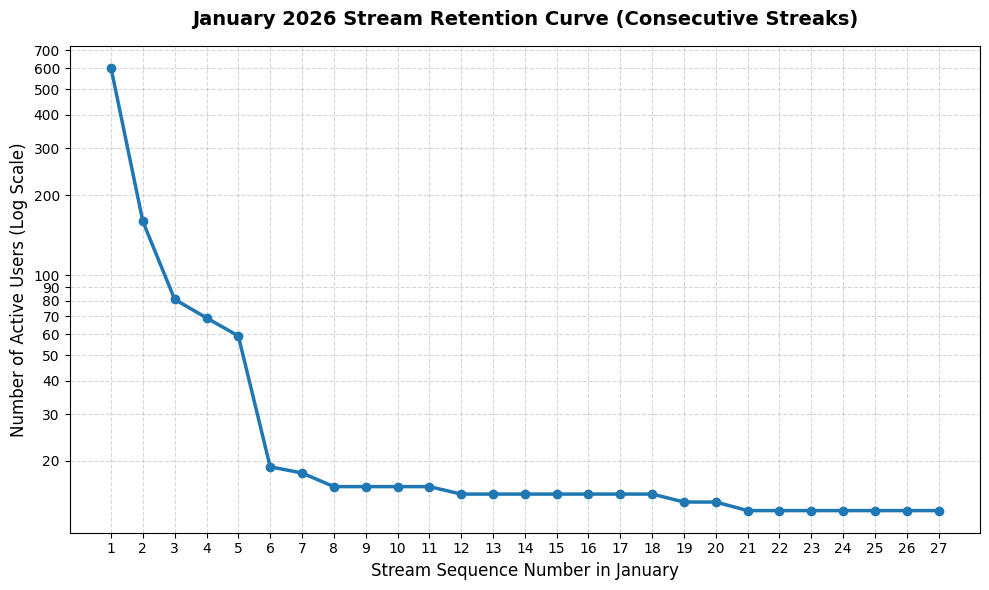

In [10]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# 7. Filter streams to January 2026 only
jan_stream_bounds = stream_bounds[
    (stream_bounds["first_msg"].dt.year == 2026)
    & (stream_bounds["first_msg"].dt.month == 1)
]
jan_streams = jan_stream_bounds.sort_values("first_msg").index.tolist()

print(f"Total January 2026 streams: {len(jan_streams)}")

# Filter dataframe for January streams
df_jan = data[data["stream"].isin(jan_streams)].copy()
jan_stream_to_idx = {stream: i for i, stream in enumerate(jan_streams)}
df_jan["stream_idx"] = df_jan["stream"].map(jan_stream_to_idx)

# 8. Calculate consecutive retention for January
attendance_jan = df_jan[["user", "stream_idx"]].drop_duplicates()
first_jan_users = attendance_jan[attendance_jan["stream_idx"] == 0][
    "user"
].unique()
attendance_jan = attendance_jan[
    attendance_jan["user"].isin(first_jan_users)
]

attendance_jan = attendance_jan.sort_values(["user", "stream_idx"])
attendance_jan["expected_idx"] = attendance_jan.groupby("user").cumcount()
consecutive_jan = attendance_jan[
    attendance_jan["stream_idx"] == attendance_jan["expected_idx"]
]

# Count how many users maintained their consecutive streak at each stream index
retention_curve = (
    consecutive_jan.groupby("stream_idx")["user"]
    .nunique()
    .reset_index(name="user_count")
)
retention_curve["stream_number"] = (
    retention_curve["stream_idx"] + 1
)  # 1-indexed for display

print("\nJanuary Stream Consecutive Retention Counts:")
print(retention_curve.to_string(index=False))

# 9. Plotting with proper Y-Axis Scaling (Log Scale)
plt.figure(figsize=(10, 6))
plt.plot(
    retention_curve["stream_number"],
    retention_curve["user_count"],
    marker="o",
    linestyle="-",
    linewidth=2.5,
    markersize=6,
    color="#1f77b4",
)

# Apply logarithmic scale to handle the steep drop-off gracefully
plt.yscale("log")

# Force standard number formatting on the log axis (e.g., 100, 500 instead of 10^2)
ax = plt.gca()
ax.yaxis.set_major_formatter(ticker.ScalarFormatter())
plt.ticklabel_format(style="plain", axis="y")

# Styling
plt.title(
    "January 2026 Stream Retention Curve (Consecutive Streaks)",
    fontsize=14,
    pad=15,
    fontweight="bold",
)
plt.xlabel("Stream Sequence Number in January", fontsize=12)
plt.ylabel("Number of Active Users (Log Scale)", fontsize=12)
plt.yscale("log")
ax = plt.gca()
ax.yaxis.set_major_locator(
    ticker.LogLocator(base=10.0, subs=(1, 2, 3, 4, 5, 6, 7, 8, 9))
)
ax.yaxis.set_major_formatter(ticker.ScalarFormatter())
plt.ticklabel_format(style="plain", axis="y")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.xticks(retention_curve["stream_number"])
plt.tight_layout()
plt.show()

February Stream Retention (Streak from Jan 1, adjusted -2):
 stream               stream_date  user_count  user_count_adjusted  feb_stream_seq
    537 2026-02-01 15:09:30+01:00          12                   10               1
    538 2026-02-05 04:20:53+01:00           5                    3               2
    539 2026-02-05 18:04:33+01:00           5                    3               3
    540 2026-02-05 23:33:55+01:00           4                    2               4
    541 2026-02-06 01:41:43+01:00           4                    2               5
    542 2026-02-06 17:58:20+01:00           4                    2               6
    543 2026-02-07 06:49:29+01:00           4                    2               7
    544 2026-02-07 18:18:25+01:00           4                    2               8
    545 2026-02-08 04:30:05+01:00           4                    2               9
    546 2026-02-08 23:05:47+01:00           4                    2              10
    547 2026-02-10 00:25:33

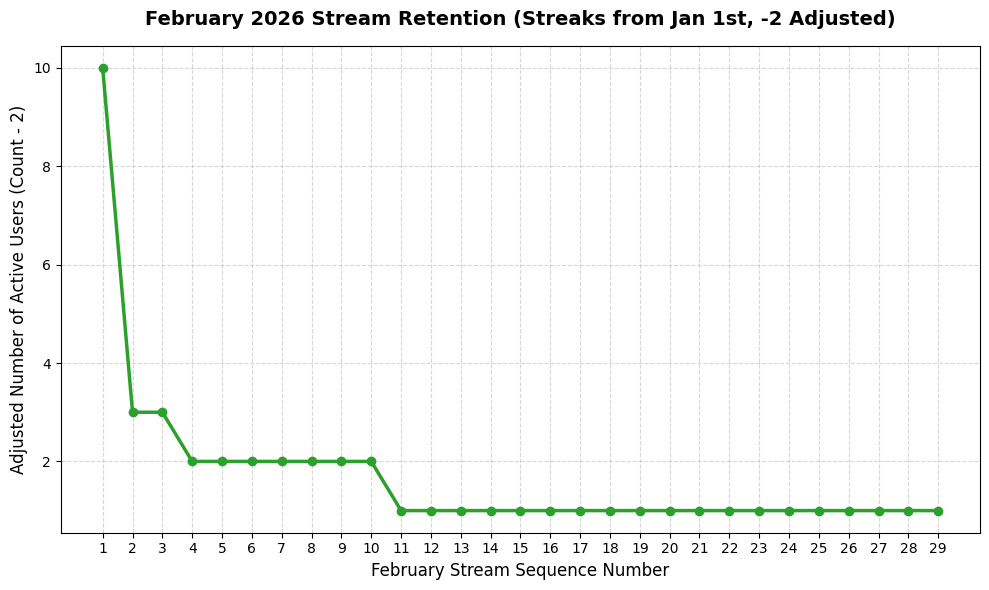

In [13]:
import matplotlib.pyplot as plt

# 7. Calculate consecutive streaks starting from the very first 2026 stream (Jan 1st baseline)
attendance_all = df_2026[["user", "stream_idx"]].drop_duplicates()
first_users = attendance_all[attendance_all["stream_idx"] == 0]["user"].unique()
attendance_all = attendance_all[attendance_all["user"].isin(first_users)]

attendance_all = attendance_all.sort_values(["user", "stream_idx"])
attendance_all["expected_idx"] = attendance_all.groupby("user").cumcount()
consecutive_all = attendance_all[
    attendance_all["stream_idx"] == attendance_all["expected_idx"]
]

# Count active users with consecutive streaks at each stream index across all 2026 streams
full_retention = (
    consecutive_all.groupby("stream_idx")["user"]
    .nunique()
    .reset_index(name="user_count")
)
full_retention["stream"] = full_retention["stream_idx"].map(idx_to_stream)
full_retention["stream_date"] = full_retention["stream"].map(
    stream_bounds["first_msg"]
)

# 8. Filter to February 2026 streams only and subtract 2 from data points
feb_retention = full_retention[
    (full_retention["stream_date"].dt.year == 2026)
    & (full_retention["stream_date"].dt.month == 2)
].copy()

# Create a 1-indexed sequence for February streams shown (1, 2, 3...)
feb_retention["feb_stream_seq"] = range(1, len(feb_retention) + 1)
feb_retention["user_count_adjusted"] = (
    feb_retention["user_count"] - 2
).clip(
    lower=0
)  # Subtract 2, ensuring it doesn't drop below 0

print("February Stream Retention (Streak from Jan 1, adjusted -2):")
print(
    feb_retention[
        [
            "stream",
            "stream_date",
            "user_count",
            "user_count_adjusted",
            "feb_stream_seq",
        ]
    ].to_string(index=False)
)

# 9. Plotting with Standard Linear Scale (No Log Scale) and -2 adjusted data
plt.figure(figsize=(10, 6))
plt.plot(
    feb_retention["feb_stream_seq"],
    feb_retention["user_count_adjusted"],
    marker="o",
    linestyle="-",
    linewidth=2.5,
    markersize=6,
    color="#2ca02c",
)

# Linear scale (default behavior, no log scale applied)
plt.title(
    "February 2026 Stream Retention (Streaks from Jan 1st, -2 Adjusted)",
    fontsize=14,
    pad=15,
    fontweight="bold",
)
plt.xlabel("February Stream Sequence Number", fontsize=12)
plt.ylabel("Adjusted Number of Active Users (Count - 2)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.xticks(feb_retention["feb_stream_seq"])
plt.tight_layout()
plt.show()
